# Bài 1

## 1a) Stochastic Gradient Descent

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [111]:
data_path="data/advertising.csv"
data = pd.read_csv(data_path)

df=pd.DataFrame(data)
df.head(5)

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [113]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [114]:
print(data.iloc[:5,:])

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [115]:
N, feature = data.shape
print(f"Bảng có {N} hàng và {feature} cột")
X = data.iloc[:, :-1].to_numpy()
y = data.iloc[:, -1].to_numpy().reshape(-1,1)
print(f"Shape của X: {X.shape}")
print(f"Shape của y: {y.shape}")

def mean_normalization(X):
    maxi = np.max(X)
    mini = np.min(X)
    avg = np.mean(X)
    X = (X - avg) / (maxi - mini)
    return X, maxi, mini, avg

X, maxi, mini, avg = mean_normalization(X)

Bảng có 200 hàng và 4 cột
Shape của X: (200, 3)
Shape của y: (200, 1)


In [116]:
print(X.shape)
print(X[:5,:])

(200, 3)
[[ 0.55042679 -0.09835864  0.00757928]
 [-0.07575405 -0.09329791 -0.07372976]
 [-0.16785931 -0.0710307   0.00791667]
 [ 0.2852446  -0.08655027 -0.02852058]
 [ 0.3840975  -0.18945175 -0.02885796]]


In [117]:
X_b = np.concatenate((np.ones((N,1)), X), axis=1)
print(X_b[:5, :])

[[ 1.          0.55042679 -0.09835864  0.00757928]
 [ 1.         -0.07575405 -0.09329791 -0.07372976]
 [ 1.         -0.16785931 -0.0710307   0.00791667]
 [ 1.          0.2852446  -0.08655027 -0.02852058]
 [ 1.          0.3840975  -0.18945175 -0.02885796]]


In [118]:
def predict(x, thetas):
    y_predict = x @ thetas
    return y_predict

def loss_compute(y_hat, y):
    loss = 0.5 * (y_hat - y) ** 2
    return loss

def gradient_compute(x, y, y_hat):
    M = x.shape[0]
    grad = (1 / M) * (x.T @ (y_hat - y))
    return grad

def update_weight(thetas, gradient, lr):
    thetas = thetas - lr * gradient
    return thetas

In [119]:
def stochastic_gradient_descent(X_b, y, n_epochs=50, learning_rate=0.00001):
    thetas = np.asarray([[1.16270837], [-0.81960489], [1.39501033], [0.29763545]])
    print(f"Shape of thetas: {thetas.shape}")
    
    thetas_path = [thetas.copy()]
    losses = []
    
    for epoch in range(n_epochs):
        loss_epoch = 0
        for i in range(N):
            random_index = i
            
            xi = X_b[random_index:random_index+1]
            yi = y[random_index:random_index+1]
            y_predict = predict(xi, thetas)
            loss = loss_compute(y_predict, yi).item()
            gradient = gradient_compute(xi, yi, y_predict)
            thetas = update_weight(thetas, gradient, learning_rate)
            thetas_path.append(thetas.copy())
            losses.append(loss)
            loss_epoch += loss
            
        # Print progress log at the end of each epoch
        loss_epoch_avg = loss_epoch / N
        if epoch % 10 == 0:
            print(f"Epoch {epoch} -- Loss : {loss_epoch_avg:.6f}")
            
    return thetas_path, losses

In [120]:
sgd_theta, losses = stochastic_gradient_descent(X_b, y, n_epochs=50, learning_rate=0.01)

Shape of thetas: (4, 1)
Epoch 0 -- Loss : 33.773217
Epoch 10 -- Loss : 2.774681
Epoch 20 -- Loss : 2.376556
Epoch 30 -- Loss : 2.258642
Epoch 40 -- Loss : 2.165582


In [121]:
print(losses)

[231.6279340126778, 41.57977069848821, 55.195151558496725, 116.41375522732167, 139.416870240043, 13.818162614137577, 50.264560288753074, 66.411203534187, 4.071010719436172, 97.99934335521762, 55.71945078097033, 119.52151576123394, 22.24092637560631, 64.59834235463735, 137.67672990701791, 194.3792102178984, 44.772526196833745, 231.27298135435674, 32.42865831823542, 63.81100691611801, 106.20930253763431, 97.74627563117265, 1.7381637398752774, 139.9196715615363, 16.733211579264427, 84.17892173134933, 58.08475993675062, 136.50250269329587, 101.54622454879421, 17.605885231575424, 134.89501045115165, 24.641821952168737, 34.60160628135653, 72.62447222508321, 23.042493338433673, 74.20171186553097, 190.78925133266415, 41.540455399922536, 10.428964979663135, 117.7809246097167, 53.721160845800775, 58.32733738465501, 95.92247747749724, 62.99128919551302, 2.8620975609820816, 43.79249159531667, 8.549632928814598, 127.70101108385958, 78.21687343739148, 4.466184251981256, 40.93124981144144, 6.71898486

In [122]:
print(np.sum(losses))

33217.851511336325


In [123]:
sgd_theta_1, losses_1 = stochastic_gradient_descent(X_b, y, n_epochs=1, learning_rate=0.01)
print(np.sum(losses_1))
print(losses_1)

Shape of thetas: (4, 1)
Epoch 0 -- Loss : 33.773217
6754.643359356192
[231.6279340126778, 41.57977069848821, 55.195151558496725, 116.41375522732167, 139.416870240043, 13.818162614137577, 50.264560288753074, 66.411203534187, 4.071010719436172, 97.99934335521762, 55.71945078097033, 119.52151576123394, 22.24092637560631, 64.59834235463735, 137.67672990701791, 194.3792102178984, 44.772526196833745, 231.27298135435674, 32.42865831823542, 63.81100691611801, 106.20930253763431, 97.74627563117265, 1.7381637398752774, 139.9196715615363, 16.733211579264427, 84.17892173134933, 58.08475993675062, 136.50250269329587, 101.54622454879421, 17.605885231575424, 134.89501045115165, 24.641821952168737, 34.60160628135653, 72.62447222508321, 23.042493338433673, 74.20171186553097, 190.78925133266415, 41.540455399922536, 10.428964979663135, 117.7809246097167, 53.721160845800775, 58.32733738465501, 95.92247747749724, 62.99128919551302, 2.8620975609820816, 43.79249159531667, 8.549632928814598, 127.7010110838595

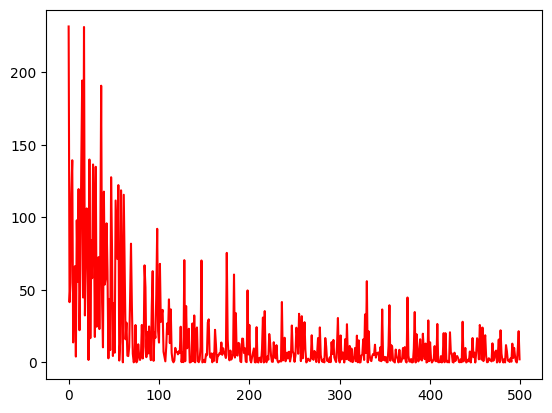

In [124]:
x_axis = list(range(500))
plt.plot(x_axis, losses[:500], color="r")
plt.show()

## 1b) Mini Batch Gradient Descent

In [125]:
shuffled_indices = np.asarray([21, 144, 17, 107, 37, 115, 167, 31, 3, 132, 179, 155, 36, 191, 182, 170, 27, 35, 162, 25, 28, 73, 172, 152, 102, 16, 185, 11, 1, 34, 177, 29, 96, 22, 76, 196, 6, 128, 114, 117, 111, 43, 57, 126, 165, 78, 151, 104, 110, 53, 181, 113, 173, 75, 23, 161, 85, 94, 18, 148, 190, 169, 149, 79, 138, 20, 108, 137, 93, 192, 198, 153, 4, 45, 164, 26, 8, 131, 77, 80, 130, 127, 125, 61, 10, 175, 143, 87, 33, 50, 54, 97, 9, 84, 188, 139, 195, 72, 64, 194, 44, 109, 112, 60, 86, 90, 140, 171, 59, 199, 105, 41, 147, 92, 52, 124, 71, 197, 163, 98, 189, 103, 51, 39, 180, 74, 145, 118, 38, 47, 174, 100, 184, 183, 160, 69, 91, 82, 42, 89, 81, 186, 136, 63, 157, 46, 67, 129, 120, 116, 32, 19, 187, 70, 141, 146, 15, 58, 119, 12, 95, 0, 40, 83, 24, 168, 150, 178, 49, 159, 7, 193, 48, 30, 14, 121, 5, 142, 65, 176, 101, 55, 133, 13, 106, 66, 99, 68, 135, 158, 88, 62, 166, 156, 2, 134, 56, 123, 122, 154])
print(f"Shape of indices: {shuffled_indices.shape}")
print(f"Shape of indices:{type(shuffled_indices)}")

Shape of indices: (200,)
Shape of indices:<class 'numpy.ndarray'>


In [126]:
def mini_batch_gradient_descent(X_b, y, n_epochs=50, minibatch_size = 20,learning_rate=0.01):

    # thetas = np.random.randn(4, 1)
    thetas = np.asarray([[1.16270837], [-0.81960489], [1.39501033], [0.29763545]])

    thetas_path = [thetas]
    losses = []

    for epoch in range(n_epochs):        
        shuffled_indices = np.asarray([21, 144, 17, 107, 37, 115, 167, 31, 3, 132, 179, 155, 36, 191, 182, 170, 27, 35, 162, 25, 28, 73, 172, 152, 102, 16, 185, 11, 1, 34, 177, 29, 96, 22, 76, 196, 6, 128, 114, 117, 111, 43, 57, 126, 165, 78, 151, 104, 110, 53, 181, 113, 173, 75, 23, 161, 85, 94, 18, 148, 190, 169, 149, 79, 138, 20, 108, 137, 93, 192, 198, 153, 4, 45, 164, 26, 8, 131, 77, 80, 130, 127, 125, 61, 10, 175, 143, 87, 33, 50, 54, 97, 9, 84, 188, 139, 195, 72, 64, 194, 44, 109, 112, 60, 86, 90, 140, 171, 59, 199, 105, 41, 147, 92, 52, 124, 71, 197, 163, 98, 189, 103, 51, 39, 180, 74, 145, 118, 38, 47, 174, 100, 184, 183, 160, 69, 91, 82, 42, 89, 81, 186, 136, 63, 157, 46, 67, 129, 120, 116, 32, 19, 187, 70, 141, 146, 15, 58, 119, 12, 95, 0, 40, 83, 24, 168, 150, 178, 49, 159, 7, 193, 48, 30, 14, 121, 5, 142, 65, 176, 101, 55, 133, 13, 106, 66, 99, 68, 135, 158, 88, 62, 166, 156, 2, 134, 56, 123, 122, 154])

        X_b_shuffled = X_b[shuffled_indices]
        y_shuffled = y[shuffled_indices]
        
        for i in range(0, N, minibatch_size):
            xi = X_b_shuffled[i:i+minibatch_size]
            yi = y_shuffled[i:i+minibatch_size]
            
            # compute output
            y_predict = predict(xi, thetas)
            
            # compute loss
            loss = loss_compute(y_predict, yi)
            
            # compute derivative of loss
            derivative_of_loss = y_predict - yi
            
            # compute derivative of parameters
            gradients = (1 / minibatch_size) * (xi.T @ derivative_of_loss)
            
            # update parameters
            thetas = thetas - learning_rate*gradients
            thetas_path.append(thetas)
            
            loss_mean = np.sum(loss)/minibatch_size
            losses.append(loss_mean)
        if epoch % 10 == 0:
            print(f"Epoch {epoch} -- Loss : {loss_mean:.6f}")

    return thetas_path, losses


In [127]:
thetas_path, losses = mini_batch_gradient_descent(X_b, y, n_epochs=50, minibatch_size = 20,learning_rate=0.01)

Epoch 0 -- Loss : 91.711942
Epoch 10 -- Loss : 17.681704
Epoch 20 -- Loss : 8.998905
Epoch 30 -- Loss : 7.269092
Epoch 40 -- Loss : 6.396734


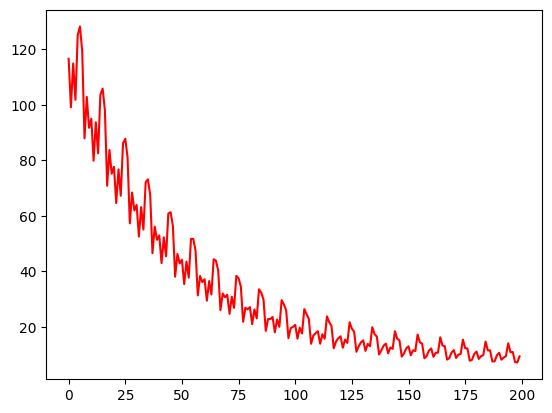

In [128]:
plt.plot(losses[:200], color="r")
plt.show()

In [129]:
mbgd_thetas, losses = mini_batch_gradient_descent(X_b, y, n_epochs=50, minibatch_size=20, learning_rate=0.01)
print(round(sum(losses), 2))


Epoch 0 -- Loss : 91.711942
Epoch 10 -- Loss : 17.681704
Epoch 20 -- Loss : 8.998905
Epoch 30 -- Loss : 7.269092
Epoch 40 -- Loss : 6.396734
8865.65


## 1c) Batch Gradient Descent

In [130]:
def batch_gradient_descent(X_b, y, n_epochs=100, learning_rate=0.01):

    # thetas = np.random.randn(4, 1) # uncomment this line for real application
    thetas = np.asarray([[1.16270837], [-0.81960489], [1.39501033],
    [0.29763545]])

    print(f"Shape of thetas: {thetas.shape}")
    thetas_path = [thetas]
    losses = []
    print(f"Shape of X_b: {X_b.shape}")
    print(f"Shape of y: {y.shape}")
    
    for epoch in range(n_epochs):
        
        y_pred = X_b.dot(thetas)
        # print(f"Shape of y_pred: {y_pred.shape}")
        
        # Compute loss
        loss = (y_pred - y) ** 2

        # Compute losss's derivative
        gradients = 2/N * X_b.T.dot(y_pred - y)
        # print(f"Shape of gradients: {gradients.shape}")
        
        # Update parameters
        thetas = thetas - learning_rate*gradients
        # print(f"Shape of thetas: {thetas.shape}")
        thetas_path.append(thetas)

        mean_loss = np.mean(loss)
        losses.append(mean_loss.item())
        if epoch % 10 == 0:
            print(f"Epoch: {epoch} --- Loss: {mean_loss}")
        
    return thetas_path, losses


In [131]:
bgd_thetas, losses = batch_gradient_descent( X_b, y, n_epochs=100, learning_rate=0.01)

Shape of thetas: (4, 1)
Shape of X_b: (200, 4)
Shape of y: (200, 1)
Epoch: 0 --- Loss: 238.06264925410917
Epoch: 10 --- Loss: 158.59076611002493
Epoch: 20 --- Loss: 107.82838942714558
Epoch: 30 --- Loss: 75.3520142992993
Epoch: 40 --- Loss: 54.52417085162759
Epoch: 50 --- Loss: 41.118208279206016
Epoch: 60 --- Loss: 32.44260532748788
Epoch: 70 --- Loss: 26.783361728055162
Epoch: 80 --- Loss: 23.04893245565113
Epoch: 90 --- Loss: 20.544134167300353


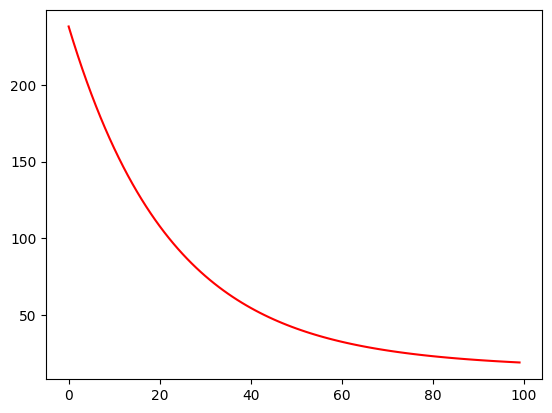

In [132]:
import matplotlib.pyplot as plt

x_axis = list(range(100))
plt.plot(x_axis, losses[:100], color="r")
plt.show()

In [133]:
print(np.sum(losses))

6716.458800156876
